# Quickstart — Health Digital Twin

A complete run of the pipeline on generated data. No SEER-Medicare access needed:
`health_dt.demo_data` produces a cohort with the same columns, dtypes, and value
ranges as the real extract, and the same latent structure — three phenotypes with
genuinely different utilisation intensity, and outcomes correlated with them.

Clone the repository, `pip install -e .`, and run this notebook top to bottom.
It takes about a minute.

**Two things differ from a real run:**

1. Population synthesis uses the `marginal` method, which needs no R but samples
   each variable independently — destroying the joint structure a real twin
   depends on. Real runs use R's `synthpop`. You will see this in the fidelity
   numbers.
2. Resource capacities are scaled down to the demo cohort. At full capacity, 500
   patients strain nothing and Level 3 reports zero unmet demand.

---

## What the pipeline does

| Level | Question | Output |
|---|---|---|
| 1 | What patterns of care exist, and what predicts them? | Phenotypes, a classifier, Markov transition matrices |
| 2 | What would a different population look like? | Synthetic cohorts and their *planned* care trajectories |
| 3 | What does the system actually deliver? | Unmet demand, queue waits, abandonment |

The quantity of interest is the gap between Level 2 (what patients need) and
Level 3 (what they get).

## Setup

In [1]:
import logging
import warnings

import numpy as np
import pandas as pd
from IPython.display import Image, display

import run_level1, run_level2, run_level3
from health_dt import config
from health_dt.demo_data import write_demo_data

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 25, "display.width", 160)

# The level scripts log their progress. Quieten them here so the notebook shows
# rendered tables instead of console text — the full logs are written to
# outputs/run_levelN.log either way.
logging.basicConfig(level=logging.WARNING, force=True)

N_PATIENTS = 500
REPLICATIONS = 3
CAPACITY_SCALE = N_PATIENTS / config.N_SYNTHETIC   # scale the system to the demo cohort

print(f"Data directory:   {config.DATA_DIR}")
print(f"Output directory: {config.OUTPUT_DIR}")

Data directory:   /home/claude/build/data
Output directory: /home/claude/build/outputs


### Generate the demo cohort

Three files, written under the names `config.py` expects — so everything
downstream runs unmodified.

In [2]:
write_demo_data(n=N_PATIENTS, seed=0)

raw = pd.read_csv(config.COMBINED_CSV)
print(f"{len(raw)} patients, {raw.shape[1]} columns")
raw[["PATIENT_ID", "age_at_followup_y", "race_grp_y", "SEERCOMBINEDSUMMARYSTAGE2000200",
     "event1", "event2", "event3", "n_ed_12fu", "mcr_cost"]].head()

Wrote demo cohort of 500 patients to /home/claude/build/data/
500 patients, 99 columns


,PATIENT_ID,age_at_followup_y,race_grp_y,SEERCOMBINEDSUMMARYSTAGE2000200,event1,event2,event3,n_ed_12fu,mcr_cost
0,1,85,Black,1,100010,000000,000000,2,7598.05
1,2,75,White,2,000000,000000,000000,2,4432.19
2,3,74,White,4,000000,000100,000000,1,4432.19
3,4,75,White,1,000000,000000,000000,2,4432.19
4,5,76,White,2,000000,rare,000000,2,7598.05


Each `event` column is one follow-up week, encoded as a zero-padded 6-bit string —
one bit per provider type (PCP, other specialty, oncology, musculoskeletal,
mental health, hospital). These map to 11 weekly states.

In [3]:
pd.DataFrame(
    [{"state": s, "label": config.STATE_LABELS[s]} for s in range(config.N_STATES)]
).set_index("state")

,label
state,
0,No Encounter
1,PCP Only
2,Other Spec Only
3,Other Spec + PCP
4,Onc/Hem Only
5,Mus_Skeletal Only
6,Mental Health Only
7,Hospital only
8,Hospital + Other Spec


---

## Level 1 — Phenotype discovery

Regroups categoricals, builds the modelling matrices, trains the phenotype
classifier, and extracts the per-phenotype Markov transition matrices that
Level 2 consumes.

In [4]:
run_level1.main()
print("Level 1 done.")


Level 1a — preprocessing


Loaded 500 patients from patients_clustered_3clus.csv


PRIMARY_PAYER_AT_DX -> GRP_PRIMARY_PAYER_AT_DX: 6 groups


MARITAL_STATUS_AT_DIAGNOSIS -> GRP_MARITAL_STATUS_AT_DIAGNOSIS: 5 groups


RADIATION_RECODE -> GRP_RADIATION_RECODE: 3 groups


...

  mcr_cost: Kruskal-Wallis = 499.00, p = 4.40e-109 ***


  saved utilization_heatmaps.png


  saved state_distribution_stacked.png



Level 1 complete. Outputs in /home/claude/build/outputs


Level 1 done.


### Which classifier won, and on what

In [5]:
display(pd.read_csv(config.out("model_comparison.csv")))
display(pd.read_csv(config.out("feature_importances.csv")).head(10))

,model,macro_f1
0,logistic_regression,0.431890
1,gradient_boosting,0.399641
2,random_forest,0.373781


,feature,importance
0,comorbid_count,0.470254
1,CHRONICKIDNEY,0.357001
2,STROKE_TIA,0.304299
3,ASTHMA,0.296598
4,HYPERT,0.261885
5,SEERCOMBINEDSUMMARYSTAGE2000200_1,0.209475
6,DEPRESSION,0.200091
7,AMI,0.185860
8,INSURANCE_RECODE_2007_2,0.168991
9,HYPERL,0.167183


Macro F1 rather than accuracy: the smallest phenotype is the clinically
interesting one, and accuracy would let a model ignore it. This number is a
ceiling on how faithfully any Level 2 scenario can be simulated — synthetic
patients get their phenotype from this classifier.

### Table 1 — do the phenotypes differ descriptively?

In [6]:
profiles = pd.read_csv(config.out("cluster_profiles.csv"))
profiles[["Cluster", "N", "age_at_followup_y (mean+/-sd)", "n_hospital_weeks (mean+/-sd)",
          "% No Encounter", "% PCP Only", "% Hospital only", "% Rare"]]

,Cluster,N,age_at_followup_y (mean+/-sd),n_hospital_weeks (mean+/-sd),% No Encounter,% PCP Only,% Hospital only,% Rare
0,0,223,74.86 +/- 5.55,1.57 +/- 1.24,90.4%,0.9%,1.0%,0.9%
1,1,182,74.36 +/- 5.43,5.46 +/- 2.20,67.3%,3.3%,3.5%,1.0%
2,2,95,74.47 +/- 5.97,10.22 +/- 3.34,39.6%,6.7%,6.9%,1.1%


### Table 2 — do they differ clinically?

In [7]:
pd.read_csv(config.out("outcome_tests.csv"))

,outcome,test,cluster_0_mean,cluster_1_mean,cluster_2_mean,statistic,p_value,significance
0,n_ed_12fu,Kruskal-Wallis,0.8430,1.7582,3.1053,122.3923,2.647615e-27,***
1,n_inpt_stay,Kruskal-Wallis,0.3722,0.8352,1.6526,102.9880,4.329444e-23,***
2,los,Kruskal-Wallis,2.2825,5.3022,9.2211,292.4571,3.117077e-64,***
3,mcr_cost,Kruskal-Wallis,4432.1900,7598.0500,11397.0700,499.0000,4.400751e-109,***


This is a gate, not a formality. A clustering that is statistically clean but
shows no outcome separation is not useful for a digital twin. Here utilisation
intensity, hospital weeks, ED visits, length of stay, and cost all rise together
across the three phenotypes — which is what makes "low / medium / high use"
a defensible reading.

### The Level 1 → Level 2 handoff

In [8]:
from health_dt.level1.transitions import format_matrix, load_transitions

transitions = load_transitions(config.out("cluster_transitions.npz"))
print("Transition matrix, phenotype 0 (rows = this week, columns = next week):\n")
print(format_matrix(transitions[0]))

Transition matrix, phenotype 0 (rows = this week, columns = next week):

              No Encount    PCP Only  Other Spec  Other Spec  Onc/Hem On  Mus_Skelet  Mental Hea  Hospital o  Hospital +  Hospital +        Rare
No Encount         0.905       0.009       0.011       0.011       0.009       0.009       0.009       0.010       0.010       0.010       0.010
PCP Only           0.907       0.010       0.010       0.000       0.000       0.021       0.010       0.000       0.010       0.000       0.031
Other Spec         0.903       0.016       0.016       0.008       0.000       0.008       0.000       0.008       0.024       0.016       0.000
Other Spec         0.891       0.008       0.017       0.008       0.008       0.025       0.000       0.008       0.008       0.025       0.000
Onc/Hem On         0.837       0.020       0.000       0.010       0.031       0.000       0.041       0.020       0.000       0.041       0.000
Mus_Skelet         0.961       0.000       0.000       0.

Everything the twin knows about how care unfolds week to week is in these
matrices. Note the strong diagonal in the top-left: patients with no encounter
this week usually have none next week either.

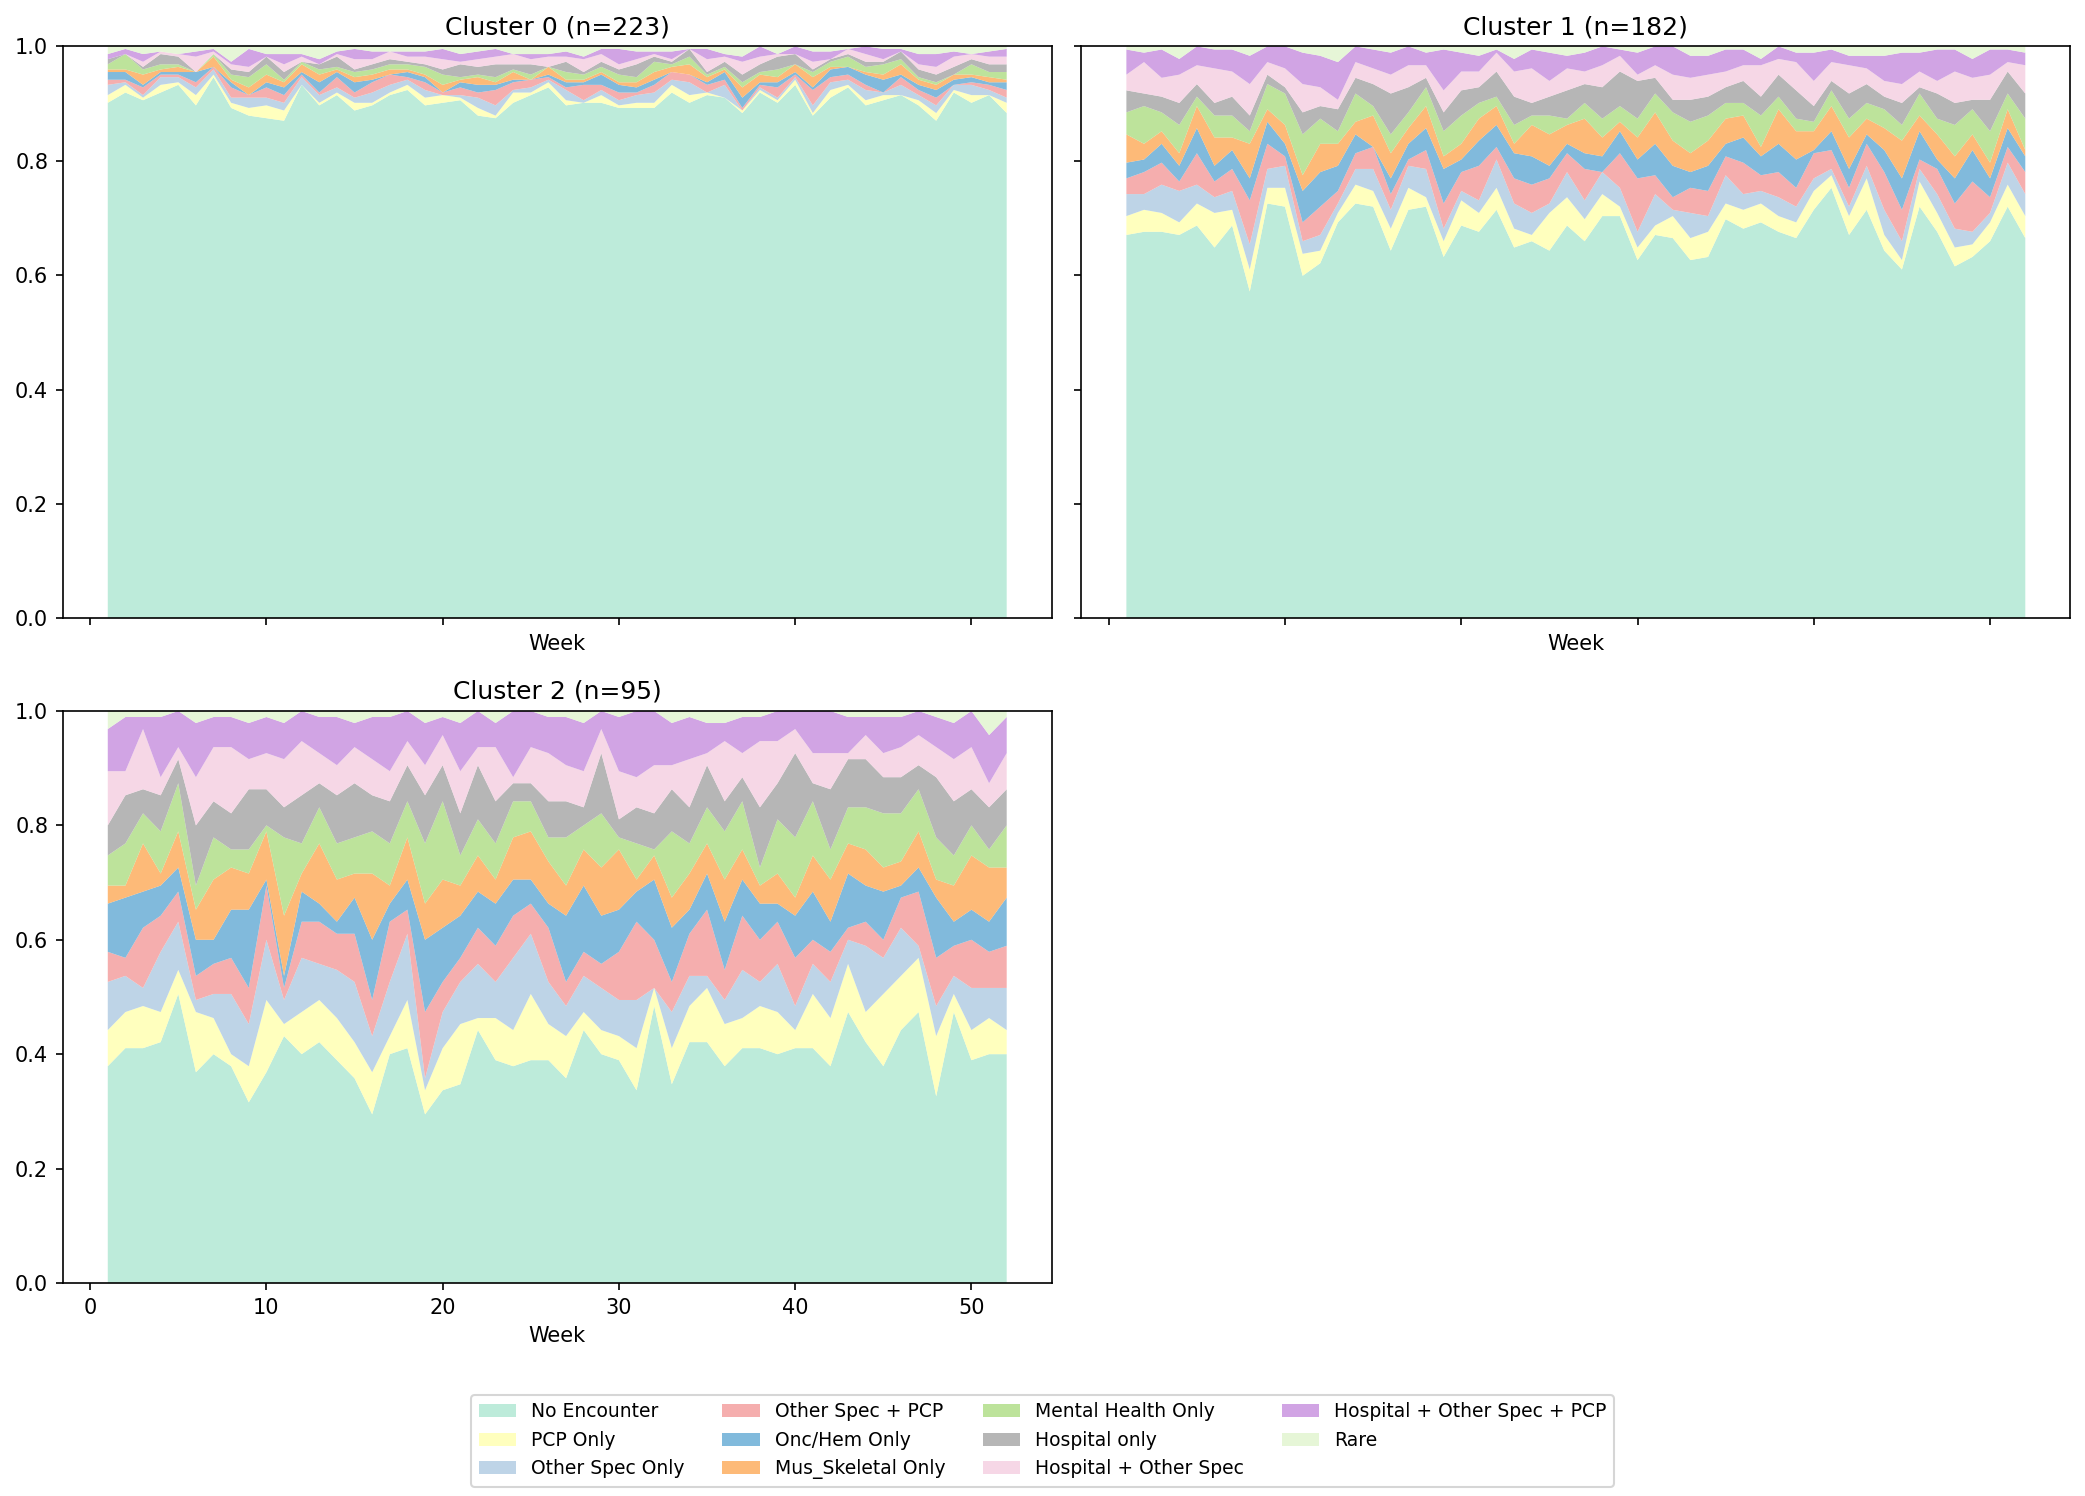

In [9]:
display(Image(config.out("state_distribution_stacked.png"), width=900))

---

## Level 2 — Building the twin

Generates a synthetic cohort, assigns each synthetic patient a phenotype using
the Level 1 classifier, and simulates their 52-week *planned* care trajectory
from that phenotype's Markov chain.

Level 1 is not re-run — Level 2 reads its saved outputs.

In [10]:
run_level2.main([
    "--method", "marginal",            # no R required; see the note at the top
    "--replications", str(REPLICATIONS),
    "--n-synthetic", str(N_PATIENTS),
])
print("Level 2 done.")


Level 2a — population synthesis (marginal)



orig_age — Observed age distribution (reference population)


  synthesised 500 patients from independent marginals



Age_5yr_Younger — Mean age shifted down 5 years


  synthesised 500 patients from independent marginals


...

  cluster 1: 0.1336


  cluster 2: 0.1835



pMSE 0.247302, ratio 76.093 (ideal ~ 1.0)



Level 2 complete. Outputs in /home/claude/build/outputs


Level 2 done.


### Is the synthetic cohort a faithful twin?

In [11]:
pd.read_csv(config.out("fidelity_orig_age.csv"))

,metric,value
0,n_real,500.000000
1,n_synthetic,500.000000
2,mix_cluster_0_real,0.446000
3,mix_cluster_0_synthetic,0.330000
4,mix_cluster_1_real,0.364000
5,mix_cluster_1_synthetic,0.378000
6,mix_cluster_2_real,0.190000
7,mix_cluster_2_synthetic,0.292000
8,frobenius_cluster_0,0.130130
9,frobenius_cluster_1,0.151260


Reading these:

- **`frobenius_cluster_*`** — distance between the real and simulated transition
  matrices, per phenotype. This is the one that matters most, because Level 3's
  conclusions are driven entirely by these matrices. The published run using
  `synthpop` had all clusters below 0.04.
- **`pMSE_ratio`** — a logistic model tries to tell real records from synthetic
  ones. Near 1.0 means it can't. The large value here is the `marginal` method
  showing its work: sampling each variable independently is easy to detect. This
  is exactly the gap that `synthpop` closes.
- **`mix_cluster_*`** — phenotype shares. Expected to match in the reference
  scenario and to *shift* in counterfactual scenarios. That shift is the point.

### The simulated trajectories

In [12]:
scenario = config.scenario(config.BASELINE_SCENARIO)
sequence_file = sorted(config.OUTPUT_DIR.glob(scenario.sequence_glob))[0]
sequences = np.load(sequence_file)

print(f"{sequence_file.name}: {sequences.shape[0]} patients x {sequences.shape[1]} weeks")
print("\nFirst 5 patients, first 15 weeks (state codes):")
display(pd.DataFrame(sequences[:5, :15], columns=[f"wk{i}" for i in range(1, 16)]))

print("Share of patient-weeks in each state:")
pd.DataFrame({
    "state": range(config.N_STATES),
    "label": [config.STATE_LABELS[s] for s in range(config.N_STATES)],
    "pct": [(sequences == s).mean() * 100 for s in range(config.N_STATES)],
}).round(2)

sequences_orig_age_seed08925.npy: 500 patients x 52 weeks

First 5 patients, first 15 weeks (state codes):


,wk1,wk2,wk3,wk4,wk5,wk6,wk7,wk8,wk9,wk10,wk11,wk12,wk13,wk14,wk15
0,9,5,6,0,0,5,8,0,4,0,3,6,2,0,0
1,0,0,1,6,8,0,0,5,1,6,0,0,0,0,6
2,0,0,0,8,0,7,0,0,0,0,0,0,0,5,0
3,0,0,9,3,6,5,8,0,0,6,5,0,2,0,5
4,0,0,0,0,0,0,9,0,0,0,0,0,0,0,0


Share of patient-weeks in each state:


,state,label,pct
0,0,No Encounter,66.98
1,1,PCP Only,3.22
2,2,Other Spec Only,3.49
3,3,Other Spec + PCP,3.88
4,4,Onc/Hem Only,3.53
5,5,Mus_Skeletal Only,3.45
6,6,Mental Health Only,3.62
7,7,Hospital only,3.72
8,8,Hospital + Other Spec,3.67
9,9,Hospital + Other Spec + PCP,3.39


---

## Level 3 — What the system can actually deliver

Each synthetic patient becomes an agent whose planned trajectory meets finite
capacity. Every week, agents declare what care they need, each resource serves up
to capacity in priority order, and the rest queue — abandoning after the drop
threshold.

In [13]:
run_level3.main(["--capacity-scale", str(CAPACITY_SCALE)])
print("Level 3 done.")


Level 3 — resource-constrained simulation


5 scenario(s), drop thresholds [4, 8, 12]


Capacities scaled by 0.0204


orig_age: 3 replications x 3 thresholds


Every agent scored acuity 0 — none of config.ACUITY_COLUMNS exist in this population, so 'acuity' queues behave as FIFO. This was true of the published runs; see docs/reproducibility.md.


...


Summary at drop threshold 8


       scenario  drop_threshold            resource  n_runs  capacity_mean  total_demand_mean  total_served_mean  total_unmet_mean  total_new_requests_mean  total_dropped_mean  queue_at_end_mean  mean_utilization_mean  peak_demand_mean  weeks_over_capacity_mean  capacity_std  total_demand_std  total_served_std  total_unmet_std  total_new_requests_std  total_dropped_std  queue_at_end_std  mean_utilization_std  peak_demand_std  weeks_over_capacity_std
   1.5x_Stage_1               8       Hospital_Beds       3           16.0        5457.333333         832.000000       4625.333333              2790.000000         1915.666667          42.333333               1.000000        252.666667                 52.000000           0.0         30.615900          0.000000        30.615900               26.286879          30.237945          4.041452              0.000000        16.289056                 0.000000
   1.5x_Stage_1               8       Mental_Health       3            4.0        3374.33333

  saved abm_resource_summary.png



Level 3 complete: 315 rows. Outputs in /home/claude/build/outputs


Level 3 done.


In [14]:
summary = pd.read_csv(config.out("abm_runs_summary.csv"))
reference = summary[
    (summary["scenario"] == config.BASELINE_SCENARIO)
    & (summary["drop_threshold"] == 8)
]
reference[["resource", "capacity_mean", "total_demand_mean", "total_served_mean",
           "total_unmet_mean", "total_unmet_std", "mean_utilization_mean"]].round(1)

,resource,capacity_mean,total_demand_mean,total_served_mean,total_unmet_mean,total_unmet_std,mean_utilization_mean
91,Hospital_Beds,16.0,5412.0,832.0,4580.0,18.1,1.0
92,Mental_Health,4.0,3231.7,208.0,3023.7,126.7,1.0
93,Musculoskeletal,13.0,2469.0,675.0,1794.0,73.2,1.0
94,Navigator,41.0,5325.7,2132.0,3193.7,65.4,1.0
95,Oncology_Hematology,8.0,2938.0,416.0,2522.0,81.7,1.0
96,Other_Specialty,67.0,5349.7,3461.3,1888.3,38.4,1.0
97,PCP,61.0,2847.3,2802.3,45.0,15.6,0.9


`total_unmet_std` is the spread across replications — it is what tells you
whether a difference between two scenarios is real or simulation noise. Reporting
a scenario comparison without it would be reporting one draw from a random
process.

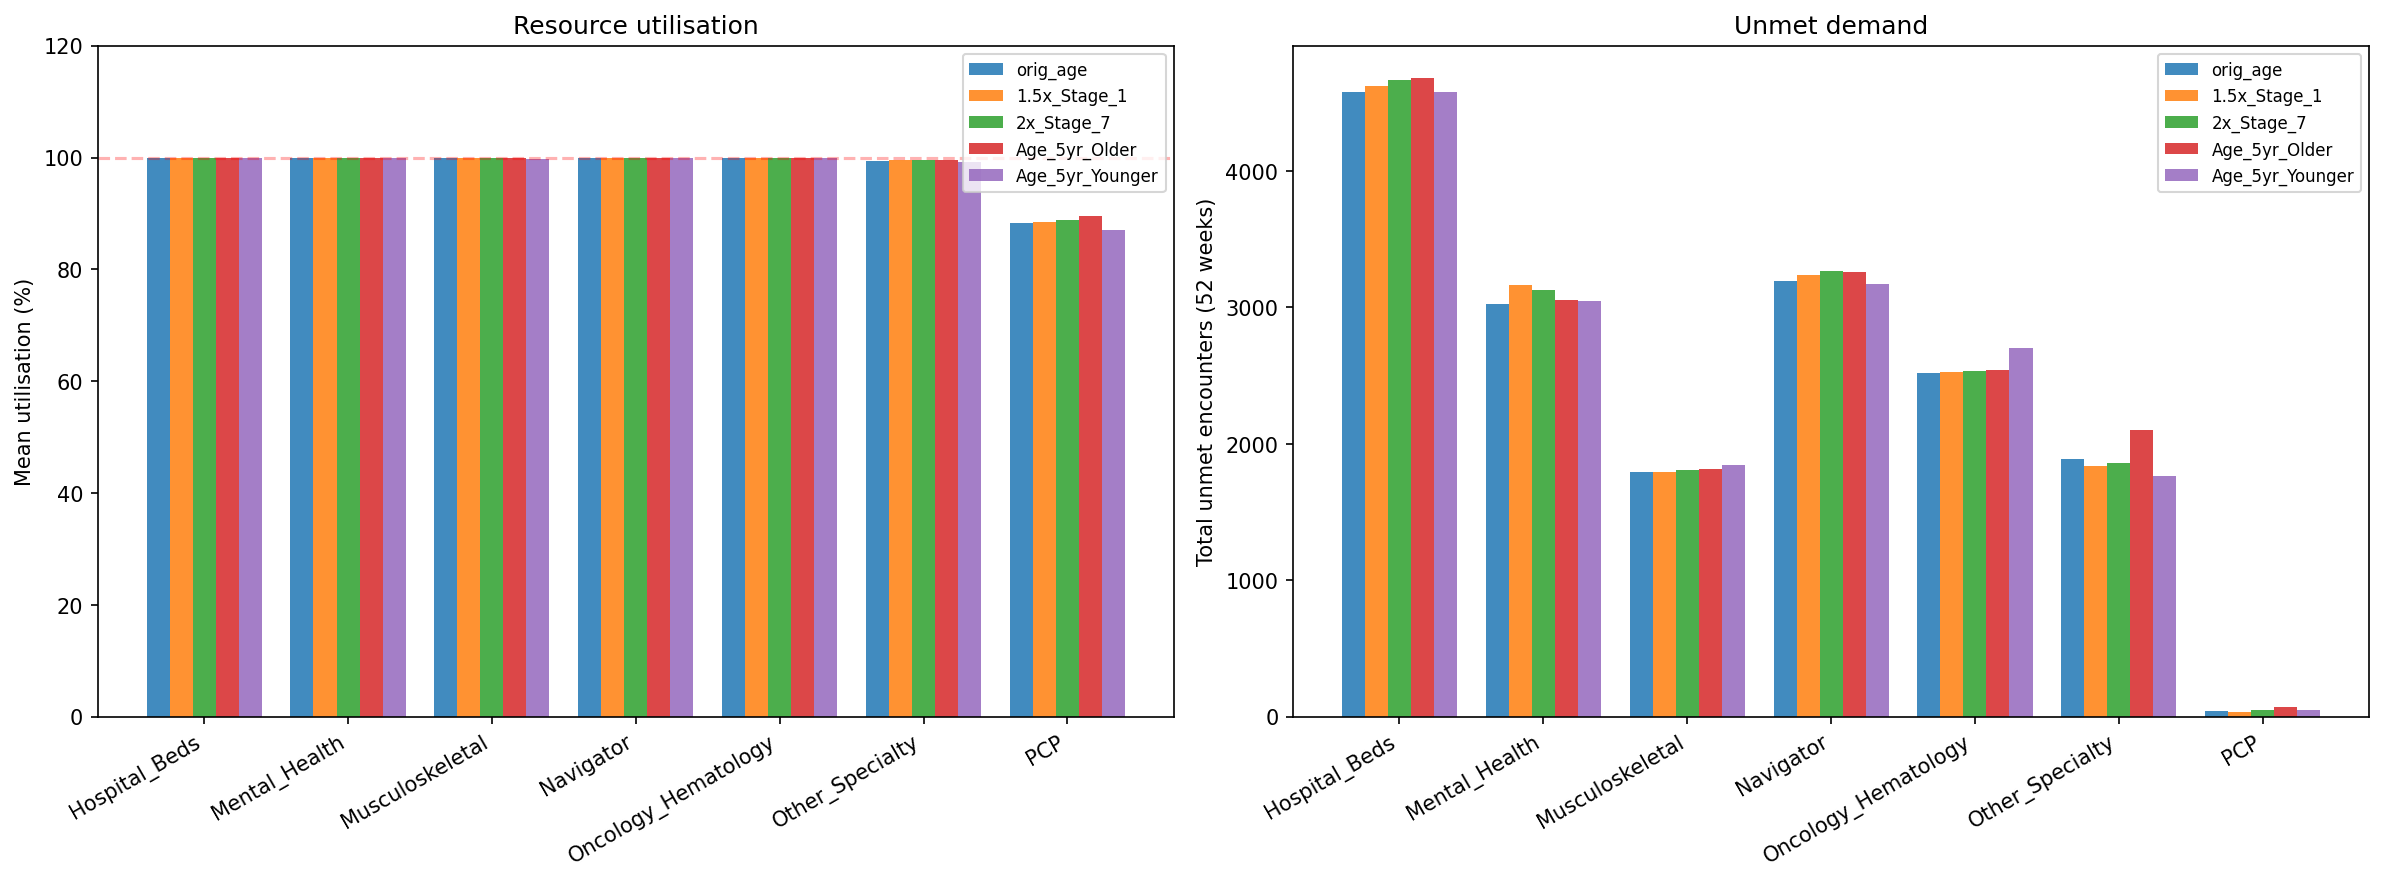

In [15]:
display(Image(config.out("abm_resource_summary.png"), width=950))

### Comparing scenarios

In [16]:
comparison = (
    summary[summary["drop_threshold"] == 8]
    .pivot_table(index="resource", columns="scenario", values="total_unmet_mean")
    .round(0)
)
comparison

scenario,1.5x_Stage_1,2x_Stage_7,Age_5yr_Older,Age_5yr_Younger,orig_age
resource,,,,,
Hospital_Beds,4625.0,4667.0,4685.0,4577.0,4580.0
Mental_Health,3166.0,3125.0,3058.0,3046.0,3024.0
Musculoskeletal,1796.0,1812.0,1816.0,1842.0,1794.0
Navigator,3240.0,3269.0,3259.0,3171.0,3194.0
Oncology_Hematology,2526.0,2535.0,2539.0,2702.0,2522.0
Other_Specialty,1838.0,1863.0,2101.0,1766.0,1888.0
PCP,37.0,45.0,73.0,48.0,45.0


Each column is a counterfactual population run through the same system at the
same capacity. Differences between columns are the effect of the population
shift alone.

With the `marginal` synthesiser these differences are not meaningful — the
synthetic cohorts do not carry the joint structure that makes an age shift
propagate into comorbidity burden. On a real run with `synthpop`, this table is
the headline result.

---

## Using the library directly

The level scripts are thin wrappers. Anything they do, you can do in a few lines
— here is a capacity what-if outside the scenario sweep.

In [17]:
from health_dt.level3.abm import run_abm
from health_dt.level3.agents import build_agents

population = pd.read_csv(config.out(scenario.clustered_csv))

results = {}
for label, factor in [("baseline", 1.0), ("+50% capacity", 1.5), ("-25% capacity", 0.75)]:
    resources = config.scale_resources(CAPACITY_SCALE * factor)
    outcome = run_abm(build_agents(population, sequences), resources=resources)
    results[label] = outcome["resources"].set_index("resource")["total_unmet"]

pd.DataFrame(results)

,baseline,+50% capacity,-25% capacity
resource,,,
PCP,35,0,2020
Other_Specialty,1902,0,3387
Oncology_Hematology,2510,1962,2778
Hospital_Beds,4599,3968,4874
Musculoskeletal,1870,59,2312
Mental_Health,3168,2925,3254
Navigator,3168,435,3949


More capacity, less unmet demand — as it must be. The value of the model is not
the direction but the magnitude, and which resource binds first.

---

## Next steps

**Run on real data.** Put the three input files in `data/` (see the README for
names and formats) and run the three level scripts in order. Drop
`--method marginal` so synthesis uses R's `synthpop`.

**Change the study design.** Everything is in `health_dt/config.py`: scenarios,
resource capacities, drop thresholds, column definitions, the state encoding.

**Replace a component.** `docs/MODULAR_UPDATE_GUIDE.md` covers every swappable
piece — clustering, classifier, synthesiser, trajectory model, and the ABM
itself — with the interface contract, the files to touch, and how to validate
afterwards.

**Read the caveats.** `docs/reproducibility.md` documents the seeds, the three
bugs found during reorganisation, and the model's known limitations. The largest:
unmet need never worsens a patient's condition, so the model probably
understates the cost of constrained capacity.